# Detection of Phishing Websites Using Machine Learning

**Dataset:** PhiUSIIL Phishing URL (Website). **Design:** reproducible, domain-grouped train/validation/test evaluation of Logistic Regression and Random Forest.

This notebook contains the research question, a testable hypothesis, a complete working data dictionary, quality checks, exploratory visualizations, preprocessing, two classifiers, confusion matrices, comparison metrics, interpretation, limitations, ethics, and references. All analysis is local; suspicious websites are never visited.

## Research question and hypothesis

**Research question:** How effectively can Logistic Regression and Random Forest distinguish phishing from legitimate websites using recorded URL and webpage features when the same observed domain cannot appear across data partitions?

**H0:** HTTPS usage and website class are independent in the training data.

**H1:** HTTPS usage is associated with website class, with a lower HTTPS prevalence among phishing websites. We use a two-sided chi-square independence test at alpha = 0.05 and check the direction separately. This is one prespecified exploratory association test, not a causal claim. It does not establish that HTTPS guarantees safety.

**Primary model metric:** phishing F1; also report phishing precision, recall, accuracy, balanced accuracy, average precision and ROC-AUC. Choose the preferred model using validation F1 before looking at final test performance. Use a fixed 0.5 classification threshold throughout.

**Source and label convention:** [UCI dataset record](https://archive.ics.uci.edu/dataset/967/phiusiil%2Bphishing%2Burl%2Bdataset) confirms that original `label=0` is phishing and `label=1` is legitimate. We create `is_phishing = 1 - label`, so positive-class metrics consistently refer to phishing. UCI lists 54 features; the local 56 columns also include the filename and target. Feature counts below are measured from the actual file.

## 1. Environment and reproducibility

Use **Python 3.12** with the packages in `requirements-analysis.txt` and select that interpreter as the notebook kernel. Place the CSV in `data/raw/` at the repository root and run all cells in order. No network access is required during execution. Fixed random seeds make the split and estimators repeatable; timing can vary by computer. Tables and project artifacts are written under `reports/results/`.

In [1]:
from pathlib import Path
import sys, hashlib, json, time, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import chi2_contingency
import sklearn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, average_precision_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from IPython.display import display, Markdown

SEED = 42
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'notebooks').is_dir() and (p / 'data/raw').is_dir()
             and (p / 'requirements-analysis.txt').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run the notebook from this repository or its notebooks directory.')
OUT = ROOT / 'reports' / 'results'
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 80)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.grid': True, 'grid.alpha': .2})
environment = {'python': platform.python_version(), 'pandas': pd.__version__,
    'numpy': np.__version__, 'scipy': scipy.__version__, 'scikit-learn': sklearn.__version__}
display(pd.Series(environment, name='Version').to_frame())
print('Interpreter:', sys.executable)
def show_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close('all')

,Version
python,3.12.10
pandas,3.0.2
numpy,2.4.4
scipy,1.17.1
scikit-learn,1.8.0


Interpreter: C:\Users\Hakan ORHAN\AppData\Local\Programs\Python\Python312\python.exe


## 2. Load and inspect the original data

The CSV is kept unchanged. A SHA-256 fingerprint identifies the exact input used for this run. Raw URLs and page titles are not displayed as clickable links or interpreted as HTML.

In [2]:
DATA_PATH = ROOT / 'data' / 'raw' / 'PhiUSIIL_Phishing_URL_Dataset.csv'
if not DATA_PATH.is_file():
    raise FileNotFoundError('Place PhiUSIIL_Phishing_URL_Dataset.csv in data/raw/ at the repository root.')
fingerprint = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw = pd.read_csv(DATA_PATH)
assert raw['label'].notna().all() and set(raw['label'].unique()) == {0, 1}
print(f'Raw shape: {raw.shape[0]:,} rows x {raw.shape[1]} columns')
print('SHA-256:', fingerprint)
print(f'Memory: {raw.memory_usage(deep=True).sum()/1024**2:.1f} MiB')
display(raw.drop(columns=['URL', 'Domain', 'Title', 'FILENAME']).head())
schema = pd.DataFrame({'Data type': raw.dtypes.astype(str),
    'Unique values': raw.nunique(dropna=False), 'Missing values': raw.isna().sum()})
display(schema)

Raw shape: 235,795 rows x 56 columns
SHA-256: a236549cd369cd80bd478ff8e1779cbf44c58d5c3f79f7a51a1adbed7d06d1c6
Memory: 120.1 MiB


,URLLength,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,31,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,23,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,29,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,26,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,33,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


,Data type,Unique values,Missing values
FILENAME,str,235795,0
URL,str,235370,0
URLLength,int64,482,0
Domain,str,220086,0
DomainLength,int64,101,0
IsDomainIP,int64,2,0
TLD,str,695,0
URLSimilarityIndex,float64,36360,0
CharContinuationRate,float64,898,0
TLDLegitimateProb,float64,465,0


## 3. Complete working data dictionary

The label mapping and filename role are explicitly documented by UCI. UCI's public variable table does not provide detailed extraction formulas for most features. The following **working definitions are interpretations of the column names**, not verified extraction algorithms. In particular, score normalization, ratio denominators, obfuscation rules, keyword matching rules and title-matching formulas require the original feature extractor for exact replication. Original misspellings are retained to match the CSV.

Unverified reference-based quantities (`URLSimilarityIndex`, `TLDLegitimateProb`, `URLCharProb`) are excluded from the primary models as a precaution, not because leakage has been proved. Raw identifiers/text and TLD are also excluded; the classifiers use numeric features, so categorical feature encoding is not needed. The target is explicitly recoded.

In [3]:
definitions = {'FILENAME': 'Source file identifier; UCI states this field can be ignored.', 'URL': 'Recorded website address; raw text, excluded from predictors.', 'URLLength': 'Recorded URL length.', 'Domain': 'Recorded domain or host string; used for grouping, not prediction.', 'DomainLength': 'Recorded domain length.', 'IsDomainIP': 'Indicator that the domain is represented by an IP address.', 'TLD': 'Top-level domain text; excluded from the numeric-only experiment.', 'URLSimilarityIndex': 'URL similarity score; reference set and exact formula are not established here.', 'CharContinuationRate': 'Character-continuation measure; exact formula requires the extractor.', 'TLDLegitimateProb': 'Estimated legitimacy probability associated with the TLD; reference population unknown.', 'URLCharProb': 'URL character probability measure; reference distribution unknown.', 'TLDLength': 'Recorded length of the top-level domain.', 'NoOfSubDomain': 'Recorded number of subdomains.', 'HasObfuscation': 'Indicator of detected URL obfuscation.', 'NoOfObfuscatedChar': 'Number of characters identified as obfuscated.', 'ObfuscationRatio': 'Ratio of obfuscated characters; denominator requires extractor documentation.', 'NoOfLettersInURL': 'Number of letters in the URL.', 'LetterRatioInURL': 'Letter proportion in the URL; exact denominator unverified.', 'NoOfDegitsInURL': 'Number of digits in the URL; original column spelling retained.', 'DegitRatioInURL': 'Digit proportion in the URL; original spelling retained.', 'NoOfEqualsInURL': 'Number of equals signs in the URL.', 'NoOfQMarkInURL': 'Number of question marks in the URL.', 'NoOfAmpersandInURL': 'Number of ampersands in the URL.', 'NoOfOtherSpecialCharsInURL': 'Number of other special characters in the URL; character set unverified.', 'SpacialCharRatioInURL': 'Special-character proportion; original spelling retained.', 'IsHTTPS': 'Indicator that the recorded URL uses HTTPS.', 'LineOfCode': 'Recorded webpage source-code line count.', 'LargestLineLength': 'Length of the longest recorded source-code line.', 'HasTitle': 'Indicator of a webpage title.', 'Title': 'Recorded webpage title text; excluded from predictors.', 'DomainTitleMatchScore': 'Domain-to-title matching score; exact algorithm unverified.', 'URLTitleMatchScore': 'URL-to-title matching score; exact algorithm unverified.', 'HasFavicon': 'Indicator of a favicon.', 'Robots': 'Robots-related indicator; exact detection rule unverified.', 'IsResponsive': 'Responsive-page indicator; exact detection rule unverified.', 'NoOfURLRedirect': 'Recorded URL redirect count.', 'NoOfSelfRedirect': 'Recorded self-redirect count.', 'HasDescription': 'Indicator of a webpage description.', 'NoOfPopup': 'Recorded popup count.', 'NoOfiFrame': 'Recorded iframe count.', 'HasExternalFormSubmit': 'Indicator of a form submitting externally.', 'HasSocialNet': 'Indicator of social-network references.', 'HasSubmitButton': 'Indicator of a submit button.', 'HasHiddenFields': 'Indicator of hidden form fields.', 'HasPasswordField': 'Indicator of a password input field.', 'Bank': 'Bank-related keyword indicator; vocabulary and matching rule unverified.', 'Pay': 'Payment-related keyword indicator; vocabulary and matching rule unverified.', 'Crypto': 'Cryptocurrency-related keyword indicator; vocabulary and matching rule unverified.', 'HasCopyrightInfo': 'Indicator of copyright information.', 'NoOfImage': 'Recorded image count.', 'NoOfCSS': 'Recorded CSS resource count.', 'NoOfJS': 'Recorded JavaScript resource count.', 'NoOfSelfRef': 'Recorded self-reference count.', 'NoOfEmptyRef': 'Recorded empty-reference count.', 'NoOfExternalRef': 'Recorded external-reference count.', 'label': 'Original target: 0 = phishing, 1 = legitimate; confirmed by UCI.'}
assert set(definitions) == set(raw.columns), 'Dictionary must cover every original column.'
excluded = ['FILENAME', 'URL', 'Domain', 'Title', 'TLD',
            'URLSimilarityIndex', 'TLDLegitimateProb', 'URLCharProb']
dictionary = schema.copy()
dictionary['Working meaning'] = pd.Series(definitions)
dictionary['Role'] = ['Original target' if c == 'label' else
    ('Excluded / audit only' if c in excluded else 'Numeric predictor') for c in dictionary.index]
display(dictionary)
dictionary.to_csv(OUT / 'data_dictionary.csv', index_label='Variable')

,Data type,Unique values,Missing values,Working meaning,Role
FILENAME,str,235795,0,Source file identifier; UCI states this field ...,Excluded / audit only
URL,str,235370,0,"Recorded website address; raw text, excluded f...",Excluded / audit only
URLLength,int64,482,0,Recorded URL length.,Numeric predictor
Domain,str,220086,0,Recorded domain or host string; used for group...,Excluded / audit only
DomainLength,int64,101,0,Recorded domain length.,Numeric predictor
IsDomainIP,int64,2,0,Indicator that the domain is represented by an...,Numeric predictor
TLD,str,695,0,Top-level domain text; excluded from the numer...,Excluded / audit only
URLSimilarityIndex,float64,36360,0,URL similarity score; reference set and exact ...,Excluded / audit only
CharContinuationRate,float64,898,0,Character-continuation measure; exact formula ...,Numeric predictor
TLDLegitimateProb,float64,465,0,Estimated legitimacy probability associated wi...,Excluded / audit only


## 4. Missing values, duplicates and integrity checks

Missing values, blank strings and possible placeholder strings are counted separately. A placeholder such as `unknown` is flagged for review rather than automatically replaced. Numeric infinities would be replaced by NaN for train-fitted median imputation. Duplicate URLs with contradictory labels would require investigation and stop execution; otherwise the first exact-URL record is retained under a fixed, label-independent rule. The duplicate audit covers the input, whereas class-dependent EDA below uses the training partition only.

In [4]:
text_columns = raw.select_dtypes(exclude='number').columns.tolist()
quality = pd.DataFrame({'Missing count': raw.isna().sum(),
    'Missing percent': raw.isna().mean()*100, 'Blank string count': 0, 'Potential placeholder count': 0})
for c in text_columns:
    s = raw[c].astype('string').str.strip()
    quality.loc[c, 'Blank string count'] = int(s.eq('').sum())
    quality.loc[c, 'Potential placeholder count'] = int(s.str.lower().isin(['unknown','none','null','nan','n/a','-']).sum())
display(quality)
quality.to_csv(OUT / 'quality_audit.csv', index_label='Variable')
conflicting_urls = raw.groupby('URL')['label'].nunique().gt(1).sum()
assert conflicting_urls == 0, 'Contradictory labels for the same URL require investigation.'
duplicate_url_count = int(raw['URL'].duplicated().sum())
print('Exact duplicate rows:', int(raw.duplicated().sum()))
print('Repeated exact URLs:', duplicate_url_count)
print('Conflicting URL labels:', conflicting_urls)
data = raw.drop_duplicates(subset='URL', keep='first').copy().reset_index(drop=True)
data['is_phishing'] = 1 - data['label']
data['class_name'] = data['is_phishing'].map({0:'Legitimate', 1:'Phishing'})
numeric_features = [c for c in raw.select_dtypes(include='number').columns if c != 'label' and c not in excluded]
infinity_count = int(np.isinf(data[numeric_features].to_numpy()).sum())
print('Non-finite predictor values:', infinity_count)
data[numeric_features] = data[numeric_features].replace([np.inf, -np.inf], np.nan)
print(f'After exact-URL deduplication: {len(data):,} rows')
print('Missing numeric cells after infinity replacement:', int(data[numeric_features].isna().sum().sum()))
print('No missing values are filled globally. Median imputers will be fitted inside each training pipeline.')

,Missing count,Missing percent,Blank string count,Potential placeholder count
FILENAME,0,0.0,0,0
URL,0,0.0,0,0
URLLength,0,0.0,0,0
Domain,0,0.0,0,0
DomainLength,0,0.0,0,0
IsDomainIP,0,0.0,0,0
TLD,0,0.0,0,0
URLSimilarityIndex,0,0.0,0,0
CharContinuationRate,0,0.0,0,0
TLDLegitimateProb,0,0.0,0,0


Exact duplicate rows: 0
Repeated exact URLs: 425
Conflicting URL labels: 0
Non-finite predictor values: 0
After exact-URL deduplication: 235,370 rows
Missing numeric cells after infinity replacement: 0
No missing values are filled globally. Median imputers will be fitted inside each training pipeline.


## 5. Separate training, validation and test sets before EDA

Normalize observed domain strings by trimming whitespace, lowercasing and removing a trailing dot. GroupShuffleSplit prevents an identical normalized observed domain from crossing partitions. Approximately 60% of groups are assigned to training, 20% to validation and 20% to testing. Group percentages do not guarantee exact row percentages or class stratification; actual class proportions are reported.

Exact duplicate URLs have already been removed. Domain grouping is **not** registered-domain grouping: different subdomains of the same organization or phishing campaign can still cross partitions. A Public Suffix List-based audit and a temporal external test remain future work. We do not claim campaign independence. No hyperparameter search is conducted.

In [5]:
groups = data['Domain'].astype('string').fillna('').str.strip().str.lower().str.rstrip('.')
groups = groups.where(groups.ne(''), 'missing-domain:' + data.index.astype(str))
outer = GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED)
development_idx, test_idx = next(outer.split(data, data['is_phishing'], groups))
inner = GroupShuffleSplit(n_splits=1, test_size=.25, random_state=SEED+1)
train_rel, val_rel = next(inner.split(data.iloc[development_idx], groups=groups.iloc[development_idx]))
train_idx, val_idx = development_idx[train_rel], development_idx[val_rel]
train, validation, test = [data.iloc[idx].copy() for idx in [train_idx, val_idx, test_idx]]
split_indices = {'Train':train_idx, 'Validation':val_idx, 'Test':test_idx}
for a, b in [('Train','Validation'), ('Train','Test'), ('Validation','Test')]:
    assert not set(groups.iloc[split_indices[a]]) & set(groups.iloc[split_indices[b]])
    assert not set(data.iloc[split_indices[a]]['URL']) & set(data.iloc[split_indices[b]]['URL'])
split_summary = pd.DataFrame([{'Partition':name, 'Rows':len(idx),
    'Domains':groups.iloc[idx].nunique(), 'Row percent':len(idx)/len(data)*100,
    'Phishing percent':data.iloc[idx]['is_phishing'].mean()*100} for name,idx in split_indices.items()])
display(split_summary)
split_summary.to_csv(OUT / 'split_summary.csv', index=False)
split_manifest = pd.DataFrame({'Row after deduplication':data.index, 'Partition':''})
for name, idx in split_indices.items(): split_manifest.loc[idx, 'Partition'] = name
split_manifest.to_csv(OUT / 'split_manifest.csv', index=False)
print('All domain and exact-URL overlap assertions passed.')

,Partition,Rows,Domains,Row percent,Phishing percent
0,Train,142276,132051,60.447806,43.095111
1,Validation,46462,44017,19.739984,41.963325
2,Test,46632,44018,19.812211,42.264968


All domain and exact-URL overlap assertions passed.


## 6. Exploratory data analysis — training data only

The following figures examine class balance, feature distributions, source-content differences, HTTPS prevalence, numeric associations and common TLDs. They answer distinct questions rather than simply increasing the number of charts. Validation and test features do not guide feature selection. Strong associations are dataset-specific and can reflect how websites were collected.

,Count,Percent
class_name,,
Legitimate,80962,56.904889
Phishing,61314,43.095111


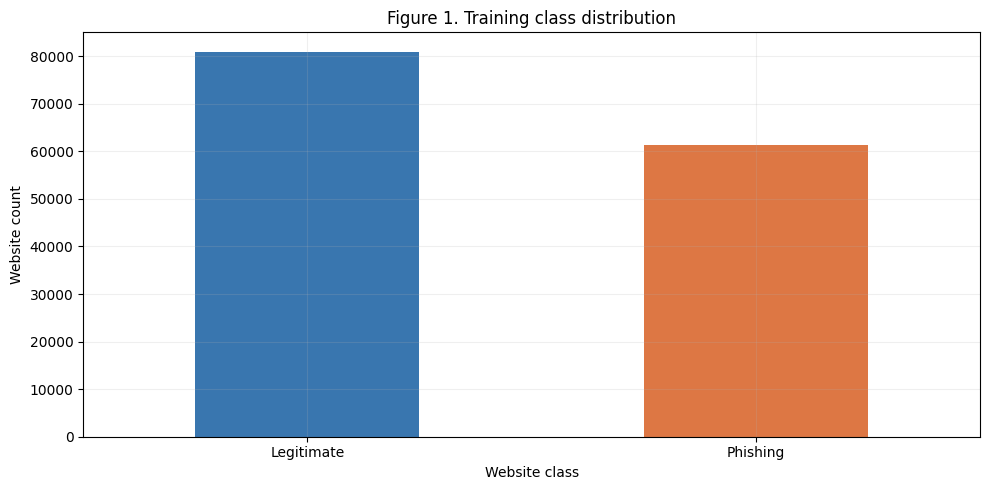

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
URLLength,142276.0,35.101521,42.394520,13.0,17.000,23.000000,28.000000,34.000,77.000,166.000,4.274000e+03
DomainLength,142276.0,21.377140,9.131412,4.0,7.000,16.000000,20.000000,24.000,38.000,56.000,1.040000e+02
IsDomainIP,142276.0,0.002776,0.052618,0.0,0.000,0.000000,0.000000,0.000,0.000,0.000,1.000000e+00
CharContinuationRate,142276.0,0.845971,0.216240,0.0,0.250,0.684211,1.000000,1.000,1.000,1.000,1.000000e+00
TLDLength,142276.0,2.762567,0.603127,2.0,2.000,2.000000,3.000000,3.000,3.000,5.000,1.300000e+01
NoOfSubDomain,142276.0,1.160189,0.608279,0.0,0.000,1.000000,1.000000,1.000,2.000,3.000,1.000000e+01
HasObfuscation,142276.0,0.002073,0.045488,0.0,0.000,0.000000,0.000000,0.000,0.000,0.000,1.000000e+00
NoOfObfuscatedChar,142276.0,0.030216,2.373317,0.0,0.000,0.000000,0.000000,0.000,0.000,0.000,4.470000e+02
ObfuscationRatio,142276.0,0.000143,0.003732,0.0,0.000,0.000000,0.000000,0.000,0.000,0.000,2.710000e-01
NoOfLettersInURL,142276.0,19.777369,27.338805,0.0,4.000,10.000000,14.000000,20.000,52.000,111.000,2.997000e+03


Constant training features: []
Numeric features retained: 47


In [6]:
class_order = ['Legitimate', 'Phishing']
counts = train['class_name'].value_counts().reindex(class_order)
display(pd.DataFrame({'Count':counts, 'Percent':counts/len(train)*100}))
ax = counts.plot.bar(color=['#3976af','#dd7744'], rot=0)
ax.set(title='Figure 1. Training class distribution', xlabel='Website class', ylabel='Website count')
show_plot('01_class_distribution')
display(train[numeric_features].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T)
constant_features = [c for c in numeric_features if train[c].nunique(dropna=False) <= 1]
print('Constant training features:', constant_features)
model_features = [c for c in numeric_features if c not in constant_features]
print('Numeric features retained:', len(model_features))

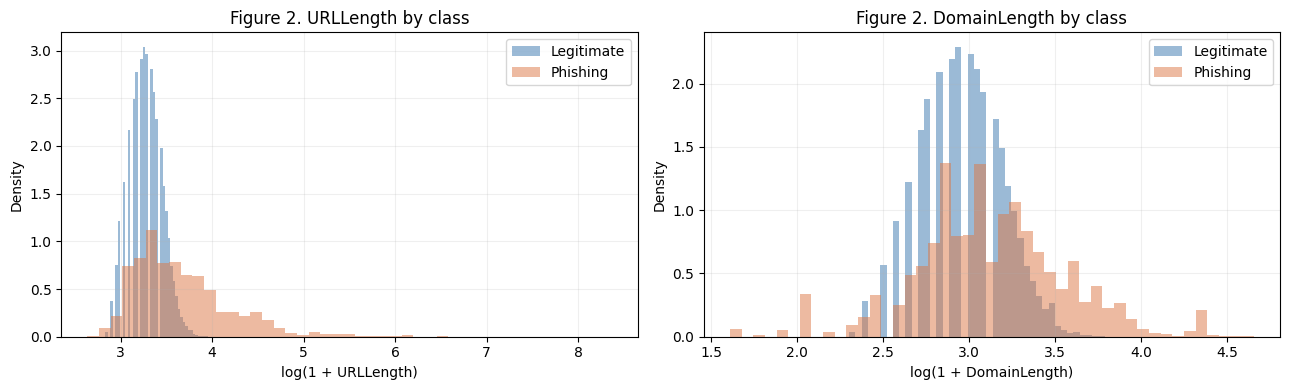

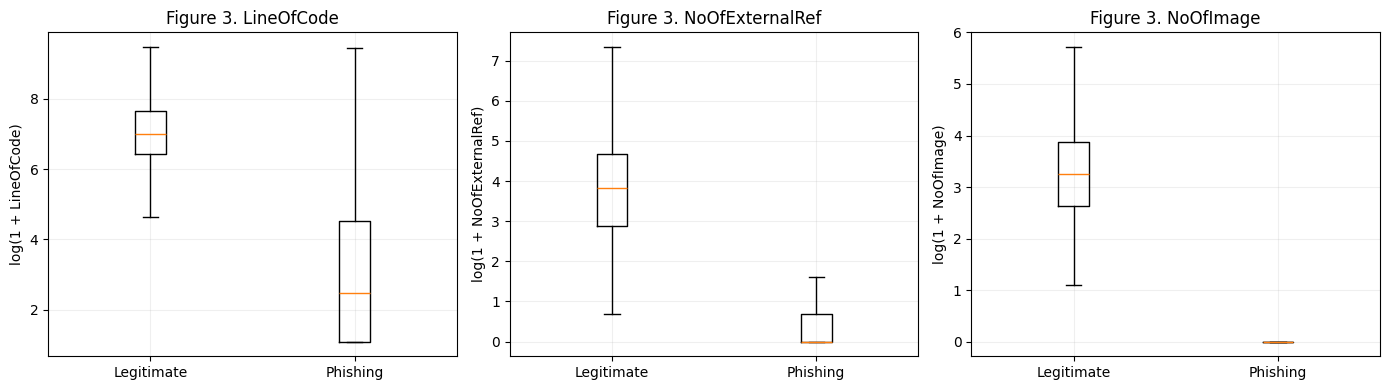

**Interpretation:** Log transforms make long-tailed URL and content measurements readable without deleting records. Boxplot outlier markers are hidden only for readability. Different content distributions could reflect both site behavior and collection or page-access failures; counts alone do not establish intent.

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13,4))
for ax,c in zip(axes, ['URLLength','DomainLength']):
    for label,color in zip(class_order,['#3976af','#dd7744']):
        v = np.log1p(train.loc[train.class_name.eq(label),c])
        ax.hist(v,bins=45,alpha=.5,density=True,label=label,color=color)
    ax.set(title=f'Figure 2. {c} by class',xlabel=f'log(1 + {c})',ylabel='Density')
    ax.legend()
show_plot('02_url_domain_lengths')
fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax,c in zip(axes,['LineOfCode','NoOfExternalRef','NoOfImage']):
    ax.boxplot([np.log1p(train.loc[train.class_name.eq(label),c].dropna()) for label in class_order],
        tick_labels=class_order,showfliers=False)
    ax.set(title=f'Figure 3. {c}',ylabel=f'log(1 + {c})')
show_plot('03_content_distributions')
display(Markdown('**Interpretation:** Log transforms make long-tailed URL and content measurements readable without deleting records. Boxplot outlier markers are hidden only for readability. Different content distributions could reflect both site behavior and collection or page-access failures; counts alone do not establish intent.'))

### Missing values and outliers: handling decision

The audit reports observed missing counts rather than assuming the source is complete. No row is dropped solely for missing numeric values; median imputation is a train-fitted safeguard. Missing or placeholder text is excluded from modeling. An IQR outlier flag is descriptive, not evidence of an error. Legitimately complex pages and intentionally long phishing URLs may be extreme, so no IQR-based trimming is applied. A fixed log1p transform reduces nonnegative numeric skew for Logistic Regression without estimating parameters from held-out data.

,Percent outside IQR fences
NoOfSubDomain,24.764542
NoOfDegitsInURL,22.312969
DegitRatioInURL,22.312969
NoOfEmptyRef,16.416683
NoOfiFrame,14.507717
URLLength,10.038938
NoOfCSS,9.734600
NoOfExternalRef,9.565914
NoOfLettersInURL,8.830723
LineOfCode,8.171441


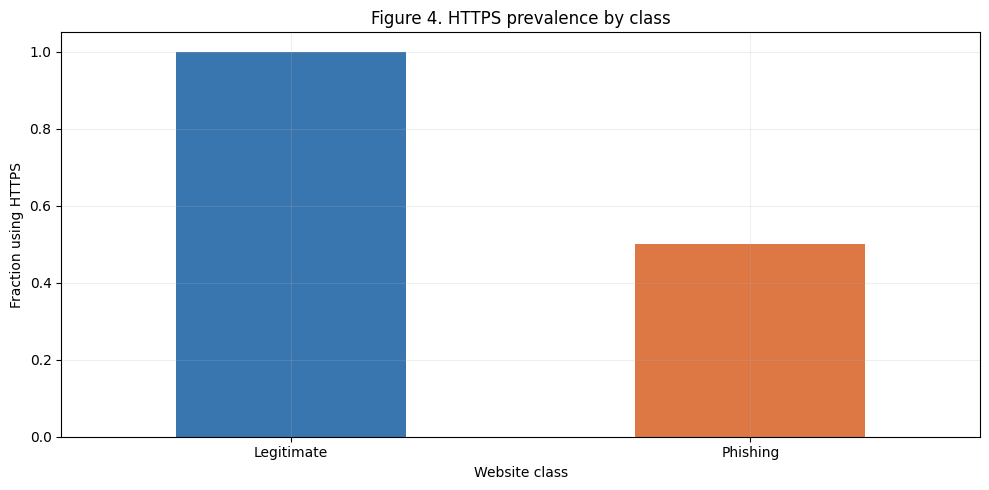

,HTTPS rate
class_name,
Legitimate,1.000000
Phishing,0.499641


**Interpretation:** A class difference in HTTPS prevalence is an association in this sample. HTTPS encrypts transport; phishing sites may also use it. A model relying heavily on this difference may fail as attacker behavior or collection practices change.

In [8]:
nonbinary = [c for c in model_features if not set(train[c].dropna().unique()).issubset({0,1})]
q1, q3 = train[nonbinary].quantile(.25), train[nonbinary].quantile(.75)
iqr = q3-q1
outliers = ((train[nonbinary] < q1-1.5*iqr) | (train[nonbinary] > q3+1.5*iqr)).mean().mul(100).sort_values(ascending=False)
display(outliers.rename('Percent outside IQR fences').to_frame())
https_rates = train.groupby('class_name')['IsHTTPS'].mean().reindex(class_order)
ax = https_rates.plot.bar(color=['#3976af','#dd7744'], rot=0)
ax.set(title='Figure 4. HTTPS prevalence by class',ylabel='Fraction using HTTPS',xlabel='Website class',ylim=(0,1.05))
show_plot('04_https_prevalence')
display(https_rates.rename('HTTPS rate').to_frame())
display(Markdown('**Interpretation:** A class difference in HTTPS prevalence is an association in this sample. HTTPS encrypts transport; phishing sites may also use it. A model relying heavily on this difference may fail as attacker behavior or collection practices change.'))

## 7. Statistical hypothesis test

The chi-square test uses training records only. Cramer's V describes association strength and the absolute prevalence difference describes practical magnitude. The standard test assumes independent observations; multiple pages from a domain can violate that assumption, making the p-value too optimistic. A second, domain-level sensitivity check uses one deterministic first record per normalized domain. Even distinct domains can share campaigns, so this does not prove independence. Large sample size can make small effects significant.

In [9]:
contingency = pd.crosstab(train['class_name'],train['IsHTTPS']).reindex(index=class_order, columns=[0,1], fill_value=0)
chi2, p_value, dof, expected = chi2_contingency(contingency, correction=False)
cramers_v = np.sqrt(chi2/contingency.to_numpy().sum())
direction = https_rates['Phishing'] < https_rates['Legitimate']
domain_sample = train.assign(_group=groups.loc[train.index]).drop_duplicates('_group',keep='first')
domain_table = pd.crosstab(domain_sample['class_name'],domain_sample['IsHTTPS']).reindex(index=class_order,columns=[0,1],fill_value=0)
domain_chi2, domain_p, _, _ = chi2_contingency(domain_table, correction=False)
display(contingency.rename(columns={0:'Not HTTPS',1:'HTTPS'}))
hypothesis_result = pd.Series({'Chi-square':chi2,'Degrees of freedom':dof,'p-value':p_value,
    'Cramers V':cramers_v,'Legitimate minus phishing HTTPS rate':https_rates['Legitimate']-https_rates['Phishing'],
    'Minimum expected cell count':expected.min(),'One record per domain p-value':domain_p})
display(hypothesis_result.to_frame('Value'))
decision = 'Reject H0' if p_value < .05 else 'Do not reject H0'
display(Markdown(f'**Result:** {decision} at alpha = 0.05. The hypothesized direction is **{direction}**. '
    f'The HTTPS-rate difference is **{100*(https_rates["Legitimate"]-https_rates["Phishing"]):.2f} percentage points**, '
    f'with Cramers V = **{cramers_v:.3f}**. A displayed p-value of zero represents floating-point underflow, not an exactly zero probability. '
    'This supports a sample association if significant, not a causal protection effect or a population-wide guarantee.'))
hypothesis_result.to_csv(OUT / 'hypothesis_test.csv', header=['Value'])

IsHTTPS,Not HTTPS,HTTPS
class_name,,
Legitimate,0,80962
Phishing,30679,30635


,Value
Chi-square,51646.620034
Degrees of freedom,1.000000
p-value,0.000000
Cramers V,0.602497
Legitimate minus phishing HTTPS rate,0.500359
Minimum expected cell count,13221.149076
One record per domain p-value,0.000000


**Result:** Reject H0 at alpha = 0.05. The hypothesized direction is **True**. The HTTPS-rate difference is **50.04 percentage points**, with Cramers V = **0.602**. A displayed p-value of zero represents floating-point underflow, not an exactly zero probability. This supports a sample association if significant, not a causal protection effect or a population-wide guarantee.

,Spearman correlation with phishing
NoOfExternalRef,-0.842801
NoOfImage,-0.842282
LineOfCode,-0.840486
NoOfSelfRef,-0.829287
NoOfJS,-0.820642
NoOfCSS,-0.801277
HasSocialNet,-0.785240
HasCopyrightInfo,-0.740361
HasDescription,-0.691418
NoOfOtherSpecialCharsInURL,0.617576


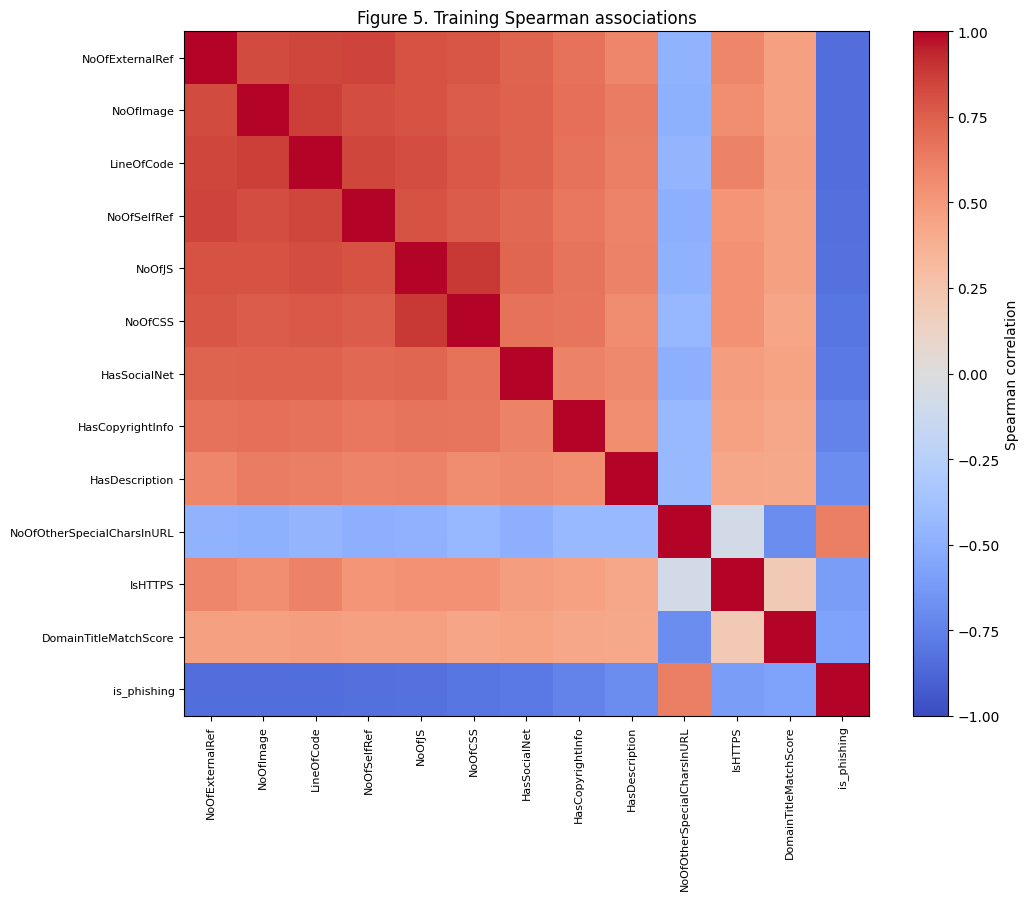

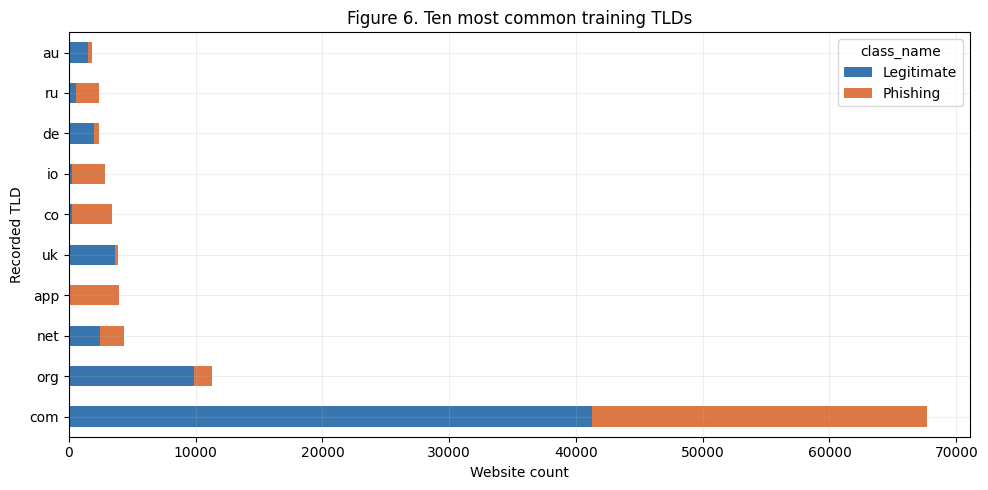

**Interpretation:** `NoOfExternalRef` has the strongest absolute training Spearman association among retained features (-0.843). Correlated page-content counts can measure overlapping information, which may make individual importance scores unstable. TLD bars show counts, not risk adjusted for internet-wide TLD prevalence. TLD is visualized but excluded from predictors.

In [10]:
correlation = train[model_features+['is_phishing']].corr(method='spearman')
ranking = correlation['is_phishing'].drop('is_phishing').dropna().sort_values(key=abs,ascending=False)
display(ranking.to_frame('Spearman correlation with phishing'))
top = ranking.head(12).index.tolist()+['is_phishing']
fig, ax = plt.subplots(figsize=(11,9))
im=ax.imshow(correlation.loc[top,top],cmap='coolwarm',vmin=-1,vmax=1)
ax.set_xticks(range(len(top)),top,rotation=90,fontsize=8)
ax.set_yticks(range(len(top)),top,fontsize=8)
ax.grid(False); ax.set_title('Figure 5. Training Spearman associations')
fig.colorbar(im,ax=ax,label='Spearman correlation')
show_plot('05_correlation_heatmap')
top_tlds = train['TLD'].value_counts().head(10).index
tld_counts = pd.crosstab(train['TLD'],train['class_name']).reindex(top_tlds).reindex(columns=class_order,fill_value=0)
ax = tld_counts.plot.barh(stacked=True,color=['#3976af','#dd7744'])
ax.set(title='Figure 6. Ten most common training TLDs',xlabel='Website count',ylabel='Recorded TLD')
show_plot('06_top_tlds')
display(Markdown(f'**Interpretation:** `{ranking.index[0]}` has the strongest absolute training Spearman association among retained features ({ranking.iloc[0]:.3f}). '
    'Correlated page-content counts can measure overlapping information, which may make individual importance scores unstable. '
    'TLD bars show counts, not risk adjusted for internet-wide TLD prevalence. TLD is visualized but excluded from predictors.'))

## 8. Leakage controls and preprocessing

- Exclude original `label`, derived `is_phishing`, class names, filename, raw URL, domain, title and TLD from X. Grouping metadata never enters the classifiers.
- Exclude three reference-based scores whose computation provenance is not verified. This is a conservative design decision; other derived scores may still contain collection artifacts.
- Determine constant columns from training data only. Median imputers and the scaler are fitted only inside pipelines on training X. No oversampling is applied.
- Both classifiers use the same numeric feature set and domain partitions. The modest class imbalance is addressed with balanced class weights and explicit minority-class metrics. A majority-class dummy baseline provides context.
- Logistic Regression uses median imputation, fixed log1p transformation and StandardScaler. Random Forest uses median imputation; tree splits do not require scaling. No categorical predictors are used, so one-hot encoding is unnecessary.
- HTML and title-match features require a fetched page. These models evaluate recorded URL-plus-content features, not a URL-only deployment scenario.

Logistic Regression provides a linear baseline in transformed feature space. Random Forest can represent nonlinear relationships and interactions. Fixed, moderate settings limit runtime and avoid repeated searching on the validation or test set.

In [11]:
X_train, X_val, X_test = [part[model_features] for part in [train,validation,test]]
y_train, y_val, y_test = [part['is_phishing'] for part in [train,validation,test]]
assert X_train.min().min() >= 0, 'log1p pipeline assumes nonnegative recorded features.'
models = {
    'Logistic Regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('log1p', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED))]),
    'Random Forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', RandomForestClassifier(n_estimators=120,max_depth=18,min_samples_leaf=2,
            class_weight='balanced',n_jobs=4,random_state=SEED))])
}
baseline = DummyClassifier(strategy='most_frequent').fit(X_train,y_train)
training_seconds = {}
for name, model in models.items():
    started = time.perf_counter()
    model.fit(X_train,y_train)
    training_seconds[name] = time.perf_counter()-started
    print(f'{name}: fitted in {training_seconds[name]:.1f} seconds')
print('Predictor count:',len(model_features))

Logistic Regression: fitted in 0.7 seconds


Random Forest: fitted in 4.0 seconds
Predictor count: 47


## 9. Validation comparison and model selection

All precision, recall and F1 values below use **phishing = 1** as the positive class. Accuracy measures all predictions; precision measures the reliability of phishing alerts; recall measures the proportion of phishing sites detected; F1 balances precision and recall. Average precision summarizes the precision-recall tradeoff across thresholds. The majority baseline can have reasonable accuracy while detecting no phishing sites. The validation winner is locked before evaluating test metrics.

In [12]:
def metric_row(name, y, probability):
    pred = (probability >= .5).astype(int)
    return {'Model':name,'Accuracy':accuracy_score(y,pred),
        'Precision (phishing)':precision_score(y,pred,zero_division=0),
        'Recall (phishing)':recall_score(y,pred,zero_division=0),
        'F1 (phishing)':f1_score(y,pred,zero_division=0),
        'Balanced accuracy':balanced_accuracy_score(y,pred),
        'Average precision':average_precision_score(y,probability),
        'ROC-AUC':roc_auc_score(y,probability)}
evaluators = {'Majority baseline':baseline, **models}
val_probabilities = {name:model.predict_proba(X_val)[:,1] for name,model in evaluators.items()}
validation_results = pd.DataFrame([metric_row(name,y_val,p) for name,p in val_probabilities.items()]).set_index('Model')
display(validation_results.round(4))
winner = validation_results.loc[list(models),'F1 (phishing)'].idxmax()
print('Preferred model selected using validation phishing F1:',winner)
validation_results.to_csv(OUT / 'validation_metrics.csv')

,Accuracy,Precision (phishing),Recall (phishing),F1 (phishing),Balanced accuracy,Average precision,ROC-AUC
Model,,,,,,,
Majority baseline,0.5804,0.0000,0.0000,0.0000,0.5000,0.4196,0.5
Logistic Regression,0.9997,0.9995,0.9997,0.9996,0.9997,1.0000,1.0
Random Forest,0.9998,0.9998,0.9997,0.9998,0.9998,1.0000,1.0


Preferred model selected using validation phishing F1: Random Forest


## 10. Final held-out test evaluation

Models remain fitted on the training partition: no refitting, hyperparameter changes or threshold tuning follows validation. Report both models on the held-out test set for comparison, while retaining the validation-selected preferred model. This is one internal domain-grouped holdout, not an external deployment validation.

,Accuracy,Precision (phishing),Recall (phishing),F1 (phishing),Balanced accuracy,Average precision,ROC-AUC,Training seconds
Model,,,,,,,,
Majority baseline,0.5774,0.0000,0.0000,0.0000,0.5000,0.4226,0.5,NaN
Logistic Regression,0.9999,0.9999,0.9997,0.9998,0.9999,1.0000,1.0,0.6700
Random Forest,0.9999,1.0000,0.9998,0.9999,0.9999,1.0000,1.0,4.0371


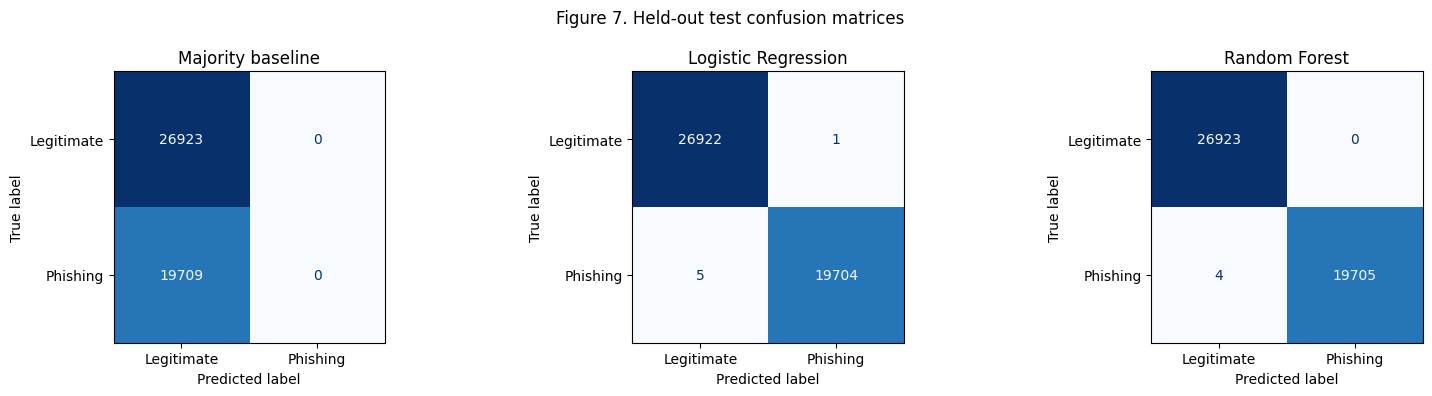

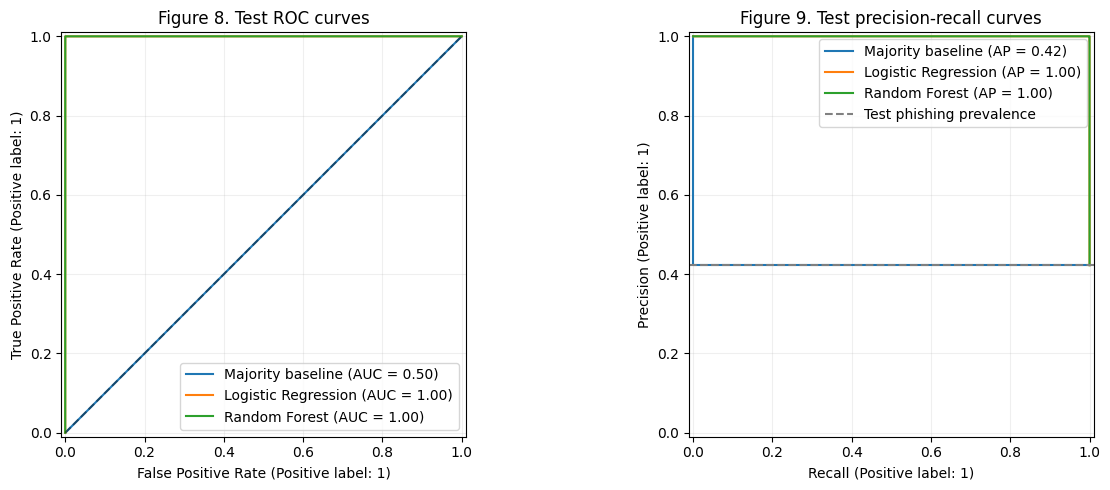

In [13]:
test_probabilities = {name:model.predict_proba(X_test)[:,1] for name,model in evaluators.items()}
test_results = pd.DataFrame([metric_row(name,y_test,p) for name,p in test_probabilities.items()]).set_index('Model')
test_results['Training seconds'] = pd.Series(training_seconds)
display(test_results.round(4))
test_results.to_csv(OUT / 'test_metrics.csv')
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,(name,p) in zip(axes,test_probabilities.items()):
    ConfusionMatrixDisplay.from_predictions(y_test,(p>=.5).astype(int),
        display_labels=['Legitimate','Phishing'],ax=ax,colorbar=False,cmap='Blues',values_format='d')
    ax.set_title(name); ax.grid(False)
fig.suptitle('Figure 7. Held-out test confusion matrices')
show_plot('07_confusion_matrices')
fig,axes=plt.subplots(1,2,figsize=(13,5))
for name,p in test_probabilities.items():
    RocCurveDisplay.from_predictions(y_test,p,name=name,ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test,p,name=name,ax=axes[1])
axes[0].plot([0,1],[0,1],'k--',alpha=.4)
axes[0].set_title('Figure 8. Test ROC curves')
axes[1].set_title('Figure 9. Test precision-recall curves')
axes[1].axhline(y_test.mean(),linestyle='--',color='gray',label='Test phishing prevalence')
axes[1].legend()
show_plot('08_09_test_curves')

## 11. Interpret errors and model behavior

False negatives are phishing websites predicted legitimate; false positives are legitimate websites flagged as phishing. Both can cause harm. Model importance below uses training-fitted coefficients and impurity importance; these do not establish causality. Forest impurity importance may favor continuous or high-cardinality features and split importance among correlated features. Logistic coefficients describe changes in log-odds per standardized transformed feature, not raw-unit changes.

,True legitimate,False alarms,Missed phishing,Detected phishing,False alarm rate,Phishing miss rate
Model,,,,,,
Majority baseline,26923,0,19709,0,0.000000,1.000000
Logistic Regression,26922,1,5,19704,0.000037,0.000254
Random Forest,26923,0,4,19705,0.000000,0.000203


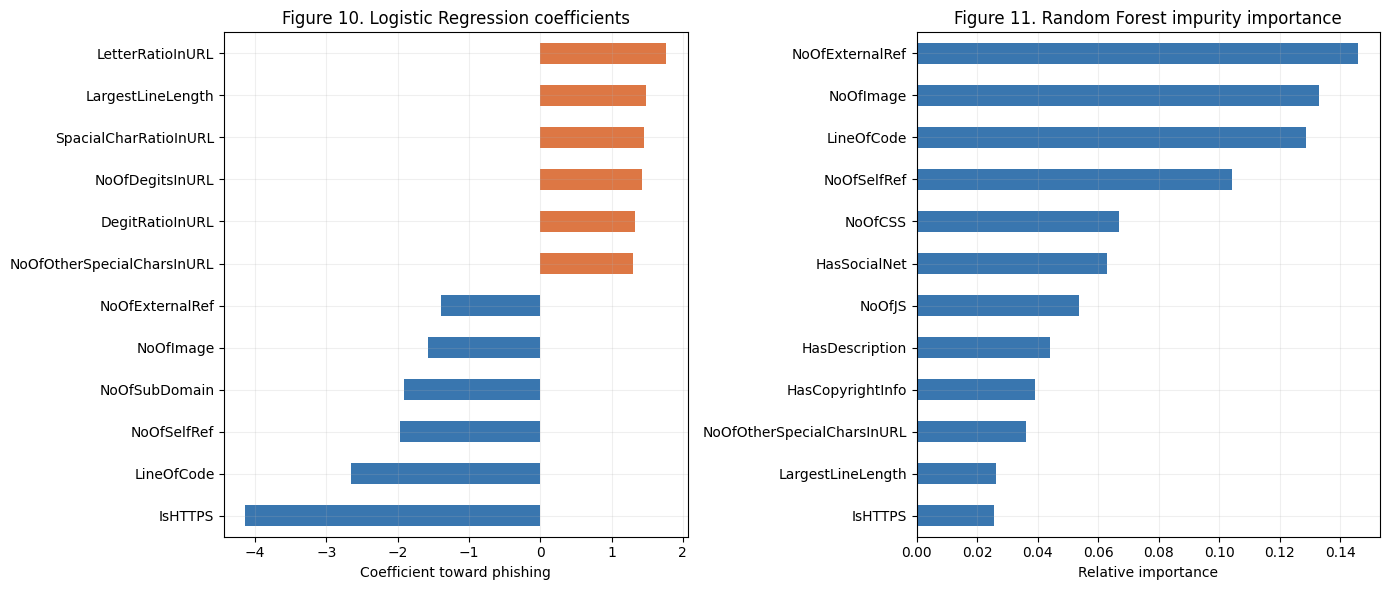

**Interpretation:** Validation selected **Random Forest**. On the internal test set it achieves accuracy **0.9999**, phishing precision **1.0000**, recall **0.9998** and F1 **0.9999**. It misses **4 phishing websites** and raises **0 false alarms**. Its test F1 difference versus Logistic Regression is **+0.0001**. This is a descriptive comparison from one split; no statistically significant superiority is claimed. The difference must be weighed against inference cost, interpretability and the operational cost of false alarms and missed attacks. Both classifiers achieve exceptionally high internal scores. This should trigger scrutiny of feature provenance, collection artifacts and residual leakage, rather than confidence that phishing detection is solved. Group separation alone cannot rule out these issues.

In [14]:
error_rows=[]
for name,p in test_probabilities.items():
    tn,fp,fn,tp=confusion_matrix(y_test,(p>=.5).astype(int),labels=[0,1]).ravel()
    error_rows.append({'Model':name,'True legitimate':int(tn),'False alarms':int(fp),
        'Missed phishing':int(fn),'Detected phishing':int(tp),
        'False alarm rate':fp/(tn+fp),'Phishing miss rate':fn/(fn+tp)})
errors=pd.DataFrame(error_rows).set_index('Model')
display(errors)
errors.to_csv(OUT / 'test_errors.csv')
coefficients=pd.Series(models['Logistic Regression']['classifier'].coef_[0],index=model_features)
importance=pd.Series(models['Random Forest']['classifier'].feature_importances_,index=model_features)
fig,axes=plt.subplots(1,2,figsize=(14,6))
coef_top=coefficients.loc[coefficients.abs().nlargest(12).index].sort_values()
coef_top.plot.barh(ax=axes[0],color=['#3976af' if v<0 else '#dd7744' for v in coef_top])
axes[0].set(title='Figure 10. Logistic Regression coefficients',xlabel='Coefficient toward phishing')
importance.nlargest(12).sort_values().plot.barh(ax=axes[1],color='#3976af')
axes[1].set(title='Figure 11. Random Forest impurity importance',xlabel='Relative importance')
show_plot('10_11_model_importance')
best = test_results.loc[winner]
best_errors=errors.loc[winner]
other=next(name for name in models if name!=winner)
gap=float(best['F1 (phishing)']-test_results.loc[other,'F1 (phishing)'])
display(Markdown(f'**Interpretation:** Validation selected **{winner}**. On the internal test set it achieves '
    f'accuracy **{best["Accuracy"]:.4f}**, phishing precision **{best["Precision (phishing)"]:.4f}**, '
    f'recall **{best["Recall (phishing)"]:.4f}** and F1 **{best["F1 (phishing)"]:.4f}**. '
    f'It misses **{int(best_errors["Missed phishing"]):,} phishing websites** and raises '
    f'**{int(best_errors["False alarms"]):,} false alarms**. Its test F1 difference versus {other} is '
    f'**{gap:+.4f}**. This is a descriptive comparison from one split; no statistically significant superiority is claimed. '
    'The difference must be weighed against inference cost, interpretability and the operational cost of false alarms and missed attacks. '
    'Both classifiers achieve exceptionally high internal scores. This should trigger scrutiny of feature provenance, collection artifacts and residual leakage, '
    'rather than confidence that phishing detection is solved. Group separation alone cannot rule out these issues.'))

## 12. Limitations, bias and ethical considerations

1. **Collection bias:** The HTTPS pattern and webpage-content differences may partly reflect collection sources, crawling failures, filtering or snapshot conditions. They may exaggerate real-world separability. Missing HTML can be a collection artifact rather than a phishing signal.
2. **Residual leakage:** Observed-domain separation and excluded reference-based features reduce specific risks but do not establish independence across registered domains, campaigns, templates or feature-generation reference data. Exact extraction provenance is unavailable here.
3. **No temporal or external validation:** No verified collection timestamps or independent current dataset are available in this project. Attacks and legitimate website behavior change; high internal performance cannot establish future performance.
4. **Class imbalance and costs:** Class weights and phishing-specific metrics address the observed imbalance. Deployment prevalence may be much lower. Precision can fall sharply when base rates change; the 0.5 threshold is a reproducible starting point, not an operationally optimized policy.
5. **Feature availability:** Content features require visiting or retrieving a page. A production crawler needs isolation, consent-aware data handling and clear rules for failed retrieval. This offline project does not access the sites.
6. **Statistical limits:** The chi-square test is observational and may overstate certainty under dependence. The single-domain-record sensitivity check remains subject to campaign dependence. One model holdout without confidence intervals or repeated grouped validation does not prove one algorithm is universally better.
7. **Ethics:** Missed phishing can expose users to credential theft; false alarms can harm legitimate businesses and access to information. Automated predictions should support review, explanations and appeal rather than irreversible blocking. Avoid sharing active malicious links, credentials or personal query-string information. Only aggregate results are exported here.
8. **Originality and reproducibility:** Interpretations are generated from this local run and its explicit design choices. Cite the original dataset and methods. Do not present this work as a reproduction of the original framework or as a production-ready detector.

## 13. Conclusion and evaluation

In [15]:
conclusion = f"""The domain-grouped comparison selected **{winner}** using validation phishing F1. On {len(test):,} held-out websites,
it achieved phishing F1 **{best['F1 (phishing)']:.4f}** and recall **{best['Recall (phishing)']:.4f}** at threshold 0.5.
The final comparison reports both linear and nonlinear classifiers rather than relying on accuracy alone.

The training-data HTTPS association test produced Cramer's V **{cramers_v:.3f}** and the decision **{decision}** at alpha 0.05;
the expected lower HTTPS prevalence among phishing records was **{direction}** in this sample.
This does not imply that HTTPS proves a website is safe.

These results support the feasibility of classification on this recorded dataset under the stated split, with important limits.
Remaining priorities are registered-domain and campaign audits, repeated grouped evaluation, confidence intervals,
feature-provenance verification, a URL-only comparison, temporal/external testing and cost-aware threshold selection.
No claim of production readiness or universal model superiority follows from the internal scores.
"""
display(Markdown(conclusion))
(OUT/'conclusion.md').write_text(conclusion,encoding='utf-8')
run_metadata={'dataset_sha256':fingerprint,'seed':SEED,'environment':environment,
    'original_rows':len(raw),'deduplicated_rows':len(data),'excluded':excluded,
    'predictors':model_features,'preferred_model_from_validation':winner,
    'positive_class':'Phishing (is_phishing=1; original label=0)',
    'threshold':.5,'split':'Observed-domain-grouped approximately 60/20/20'}
(OUT/'run_metadata.json').write_text(json.dumps(run_metadata,indent=2),encoding='utf-8')
print('Saved tables, figures, conclusion and reproducibility metadata to:',OUT.resolve())

The domain-grouped comparison selected **Random Forest** using validation phishing F1. On 46,632 held-out websites,
it achieved phishing F1 **0.9999** and recall **0.9998** at threshold 0.5.
The final comparison reports both linear and nonlinear classifiers rather than relying on accuracy alone.

The training-data HTTPS association test produced Cramer's V **0.602** and the decision **Reject H0** at alpha 0.05;
the expected lower HTTPS prevalence among phishing records was **True** in this sample.
This does not imply that HTTPS proves a website is safe.

These results support the feasibility of classification on this recorded dataset under the stated split, with important limits.
Remaining priorities are registered-domain and campaign audits, repeated grouped evaluation, confidence intervals,
feature-provenance verification, a URL-only comparison, temporal/external testing and cost-aware threshold selection.
No claim of production readiness or universal model superiority follows from the internal scores.


Saved tables, figures, conclusion and reproducibility metadata to: C:\Users\Hakan ORHAN\Desktop\pshing dataset\project_outputs


## 14. References

- Prasad, A., & Chandra, S. (2024). *PhiUSIIL Phishing URL (Website)* [Dataset]. UCI Machine Learning Repository. [Dataset, label mapping and download](https://archive.ics.uci.edu/dataset/967/phiusiil%2Bphishing%2Burl%2Bdataset). Licensed CC BY 4.0; attribution is required.
- Prasad, A., & Chandra, S. (2024). *PhiUSIIL: A diverse security profile empowered phishing URL detection framework based on similarity index and incremental learning.* Computers & Security. [DOI: 10.1016/j.cose.2023.103545](https://doi.org/10.1016/j.cose.2023.103545). Background citation; this notebook does not reproduce the paper's full method or infer undocumented extraction formulas from it.
- scikit-learn developers. [Common pitfalls and recommended practices](https://scikit-learn.org/stable/common_pitfalls.html); [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html); [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html); [RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html); [Classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html).
- SciPy developers. [chi2_contingency](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.contingency.chi2_contingency.html).

Source pages checked on October 25, 2026. Execution versions are recorded above; current online documentation may describe a newer package version.

## 15. Presentation and submission checklist

Use `reports/presentation/presentation_outline.md` for a 10-minute English presentation. Every member must speak, understand the full workflow and answer questions about the data, methods, code and results. The provided brief lists Room 318 on December 23 and December 30; confirm the assigned date with the instructor.

- [x] Executable notebook with English Markdown explanations and English figure labels.
- [x] Local dataset and source/download link; 56-variable working dictionary with uncertainty noted.
- [x] Research question, hypothesis, missing-value analysis, descriptive statistics and more than five meaningful visualizations.
- [x] Train-fitted preprocessing, two classifiers, confusion matrices, required metrics and a comparison table.
- [x] Original result interpretation, leakage/imbalance/bias discussion, limitations, ethics and English conclusion.
- [x] References and an English 8–12 minute presentation outline.
- [ ] Add group-member names; assign speaking roles, rehearse and verify that every member can explain the project.
- [ ] Confirm attendance date and any instructor-specific slide or submission format.